# Simulação

A simulação será desenvolvida utilizando Python, com as bibliotecas NumPy, Matplotlib e Seaborn.

O objetivo é gerar um sinal composto por duas senoides, calcular sua DFT, obter os espectros de magnitude e fase e identificar as frequências presentes.

Para facilitar a análise, serão utilizados 256 pontos de amostragem e uma frequência de amostragem de 256 Hz.

## Implementação

**Código da simulação:**

In [1]:
# ============================================================
# IMPORTAÇÕES E CONFIGURAÇÕES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual dos gráficos
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

FREQUÊNCIAS IDENTIFICADAS
----------------------------------------
Frequência: 10.00 Hz | Magnitude: 1.00 | Fase: -0.00 graus
Frequência: 30.00 Hz | Magnitude: 0.50 | Fase: -0.00 graus


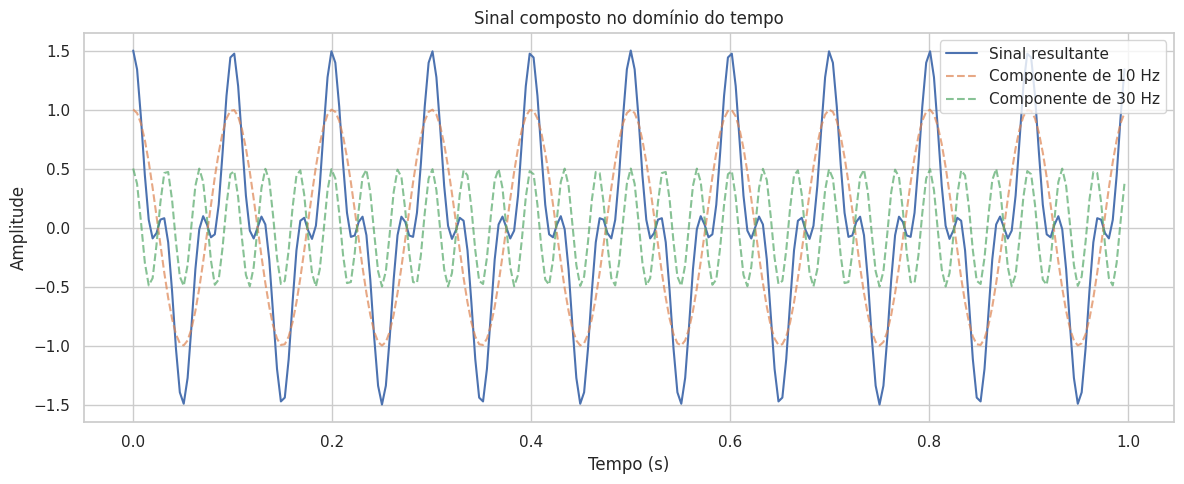

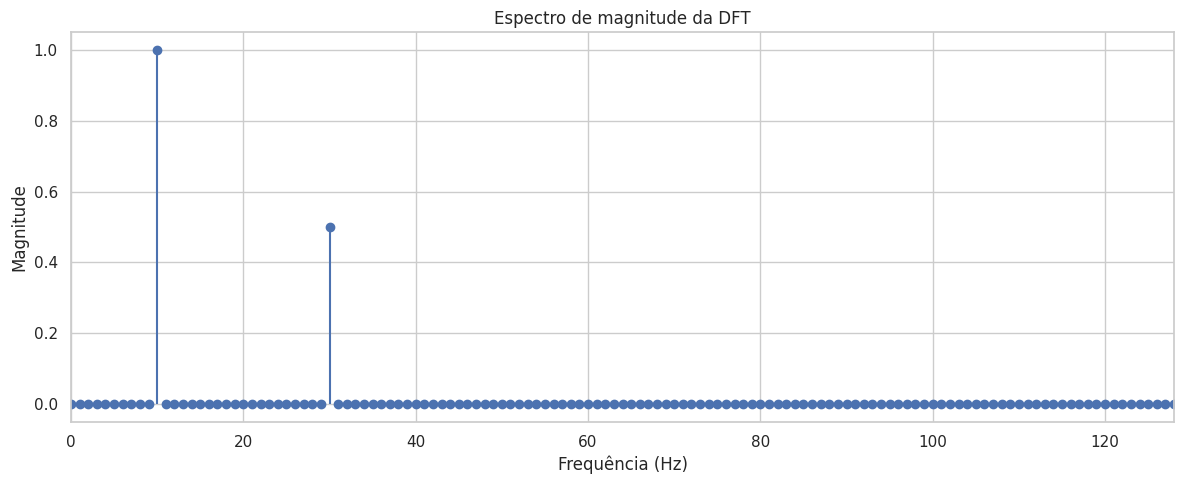

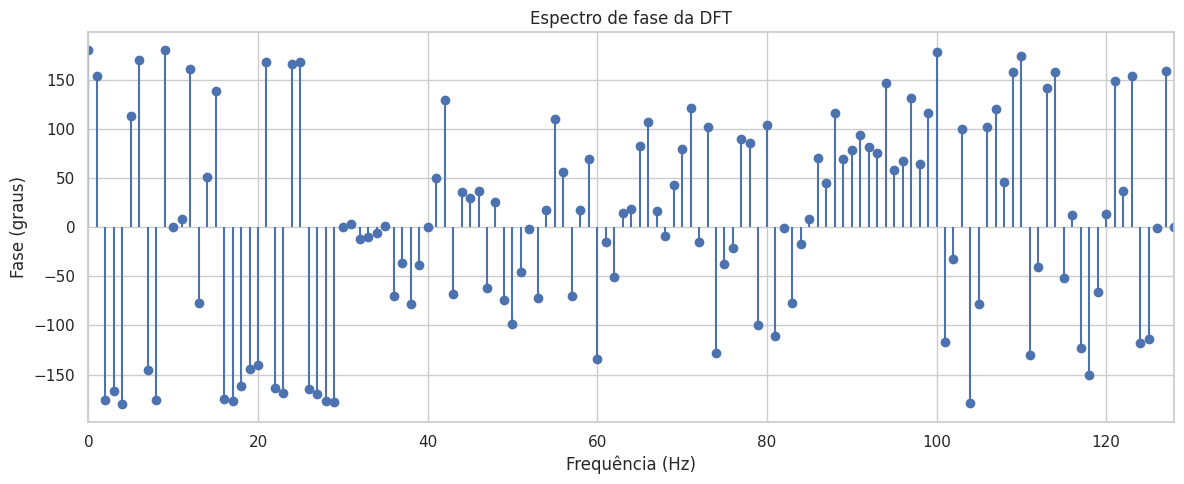


VERIFICAÇÃO DA RECONSTRUÇÃO
----------------------------------------
Erro máximo: 4.4408920985e-16


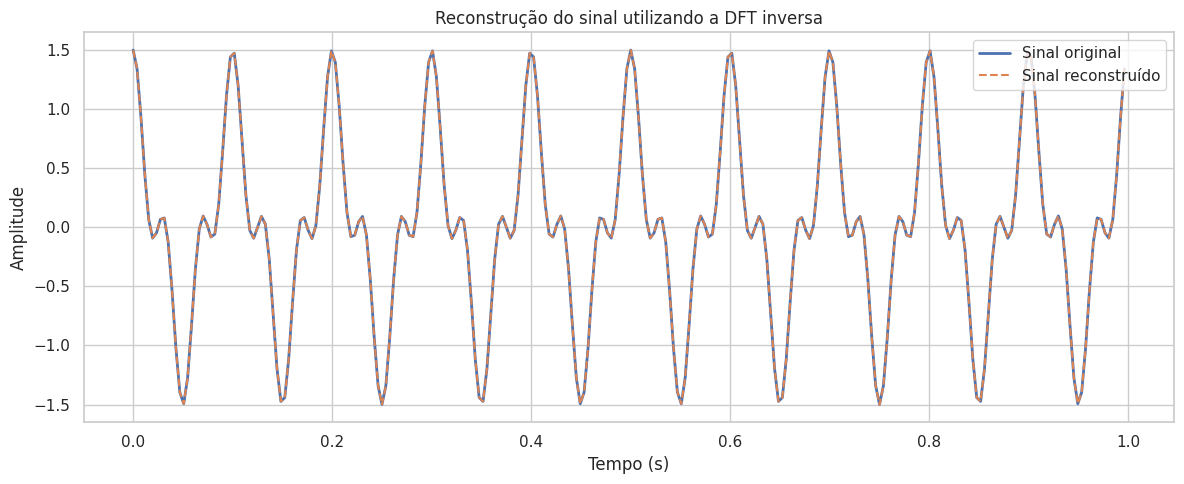

In [2]:
# ============================================================
# DEFINIÇÃO DOS PARÂMETROS DO SINAL
# ============================================================

fs = 256                 # Frequência de amostragem (Hz)
N = 256                  # Número de amostras

A1 = 1.0                 # Amplitude da primeira senoide
A2 = 0.5                 # Amplitude da segunda senoide

f1 = 10                  # Frequência da primeira senoide (Hz)
f2 = 30                  # Frequência da segunda senoide (Hz)

# Índices das amostras
n = np.arange(N)

# Vetor de tempo
t = n / fs

# ============================================================
# GERAÇÃO DO SINAL NO DOMÍNIO DO TEMPO
# ============================================================

x1 = A1 * np.cos(2 * np.pi * f1 * t)
x2 = A2 * np.cos(2 * np.pi * f2 * t)

# Sinal resultante da soma das duas componentes
x = x1 + x2

# ============================================================
# CÁLCULO DA TRANSFORMADA DISCRETA DE FOURIER
# ============================================================

X = np.fft.fft(x)

# Frequências correspondentes aos coeficientes
frequencias = np.fft.fftfreq(N, d=1/fs)

# ============================================================
# CÁLCULO DO ESPECTRO DE MAGNITUDE
# ============================================================

# Considera apenas as frequências positivas
X_positivo = X[:N//2 + 1]

frequencias_positivas = np.fft.rfftfreq(N, d=1/fs)

# Normalização da magnitude
magnitude = np.abs(X_positivo) / N

# Correção da amplitude para o espectro unilateral
magnitude[1:-1] *= 2

# ============================================================
# CÁLCULO DO ESPECTRO DE FASE
# ============================================================

fase = np.angle(X_positivo)

# Converte a fase de radianos para graus
fase_graus = np.degrees(fase)

# ============================================================
# IDENTIFICAÇÃO DAS FREQUÊNCIAS
# ============================================================

# Identifica os índices dos maiores picos
indices_picos = np.argsort(magnitude[1:])[-2:] + 1

# Organiza os picos em ordem crescente de frequência
indices_picos = indices_picos[
    np.argsort(frequencias_positivas[indices_picos])
]

print("FREQUÊNCIAS IDENTIFICADAS")
print("----------------------------------------")

for indice in indices_picos:
    print(
        f"Frequência: {frequencias_positivas[indice]:.2f} Hz | "
        f"Magnitude: {magnitude[indice]:.2f} | "
        f"Fase: {fase_graus[indice]:.2f} graus"
    )

# ============================================================
# GRÁFICO 1 - SINAL NO DOMÍNIO DO TEMPO
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    t,
    x,
    label="Sinal resultante",
    linewidth=1.5
)

plt.plot(
    t,
    x1,
    linestyle="--",
    alpha=0.7,
    label="Componente de 10 Hz"
)

plt.plot(
    t,
    x2,
    linestyle="--",
    alpha=0.7,
    label="Componente de 30 Hz"
)

plt.title("Sinal composto no domínio do tempo")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 2 - ESPECTRO DE MAGNITUDE
# ============================================================

plt.figure(figsize=(12, 5))

plt.stem(
    frequencias_positivas,
    magnitude,
    basefmt=" "
)

plt.title("Espectro de magnitude da DFT")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, fs/2)

plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 3 - ESPECTRO DE FASE
# ============================================================

plt.figure(figsize=(12, 5))

plt.stem(
    frequencias_positivas,
    fase_graus,
    basefmt=" "
)

plt.title("Espectro de fase da DFT")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Fase (graus)")
plt.xlim(0, fs/2)

plt.tight_layout()
plt.show()

# ============================================================
# VERIFICAÇÃO DA RECONSTRUÇÃO DO SINAL
# ============================================================

# Aplicação da DFT inversa
x_reconstruido = np.fft.ifft(X).real

# Cálculo do erro máximo de reconstrução
erro_maximo = np.max(np.abs(x - x_reconstruido))

print("\nVERIFICAÇÃO DA RECONSTRUÇÃO")
print("----------------------------------------")
print(f"Erro máximo: {erro_maximo:.10e}")

# ============================================================
# GRÁFICO 4 - COMPARAÇÃO ENTRE SINAL ORIGINAL E RECONSTRUÍDO
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    t,
    x,
    label="Sinal original",
    linewidth=2
)

plt.plot(
    t,
    x_reconstruido,
    "--",
    label="Sinal reconstruído",
    linewidth=1.5
)

plt.title("Reconstrução do sinal utilizando a DFT inversa")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.legend()

plt.tight_layout()
plt.show()

## Etapas da implementação

O código foi dividido em etapas para facilitar a compreensão do processamento realizado.

Inicialmente, são definidos os parâmetros das duas senoides, a frequência de amostragem e a quantidade de amostras. Em seguida, são geradas as componentes individuais e realizada a soma para formar o sinal resultante.

Na etapa seguinte, utiliza-se a função `np.fft.fft()` para calcular a DFT do sinal. Essa função implementa a Transformada Rápida de Fourier (FFT), um algoritmo computacionalmente eficiente para calcular a DFT.

Após o cálculo, são obtidos os coeficientes correspondentes às frequências positivas. A magnitude é normalizada pelo número de amostras, com correção dos componentes internos para representar adequadamente as amplitudes do sinal original.

A fase é calculada por meio da função `np.angle()`, sendo posteriormente convertida de radianos para graus.

Por fim, são identificados os dois maiores picos do espectro e realizada a reconstrução do sinal por meio de `np.fft.ifft()`, permitindo verificar a correspondência entre a sequência original e a reconstruída.